<a href="https://colab.research.google.com/github/kikijamal/SemProject_MLEngine/blob/main/Model_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. DATA UNDERSTANDING


2. DATA EXPLORATION

3.DATA PREPARATION

In [ ]:
# Libraries  (numpy, pandas) plus plotting and image tools
import os
import zipfile
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

In [ ]:
# Connect Google Drive and unzip the NEU dataset (only the first time)
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = '/content/drive/MyDrive/SemProject/archive.zip'   # where the zip is stored
DATA_DIR = '/content/neu_dataset'                            # where we unzip it

if not os.path.exists(DATA_DIR):
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(DATA_DIR)
print('Dataset ready in', DATA_DIR)

Mounted at /content/drive
Dataset ready in /content/neu_dataset


In [ ]:
# List every file in the dataset folder and put it in a DataFrame
rows = []
for folder, _, files in os.walk(DATA_DIR):
    for name in files:
        rows.append({'path': os.path.join(folder, name), 'file_name': name})

df = pd.DataFrame(rows)
print(df.shape)      # (number of files, number of columns)
df.head(10)          # first 10 rows

(3600, 2)


,path,file_name
0,/content/neu_dataset/NEU-DET/validation/annota...,inclusion_287.xml
1,/content/neu_dataset/NEU-DET/validation/annota...,scratches_283.xml
2,/content/neu_dataset/NEU-DET/validation/annota...,scratches_296.xml
3,/content/neu_dataset/NEU-DET/validation/annota...,rolled-in_scale_262.xml
4,/content/neu_dataset/NEU-DET/validation/annota...,pitted_surface_289.xml
5,/content/neu_dataset/NEU-DET/validation/annota...,patches_261.xml
6,/content/neu_dataset/NEU-DET/validation/annota...,inclusion_259.xml
7,/content/neu_dataset/NEU-DET/validation/annota...,rolled-in_scale_264.xml
8,/content/neu_dataset/NEU-DET/validation/annota...,rolled-in_scale_275.xml
9,/content/neu_dataset/NEU-DET/validation/annota...,scratches_266.xml


In [ ]:
# Work out the file type and the class (label) from the file name, e.g. crazing_1.jpg -> crazing
df['extension'] = df['file_name'].str.rsplit('.', n=1).str[-1].str.lower()
df['label'] = df['file_name'].str.rsplit('.', n=1).str[0].str.rsplit('_', n=1).str[0]

print(df['extension'].value_counts())   # which file types are in the folder
df.info()                                # columns, row count, data types

extension
xml    1800
jpg    1800
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   path       3600 non-null   object
 1   file_name  3600 non-null   object
 2   extension  3600 non-null   object
 3   label      3600 non-null   object
dtypes: object(4)
memory usage: 112.6+ KB


In [ ]:
# A hash is a short code made from the file contents; identical files give identical codes
def file_hash(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

df['hash'] = df['path'].apply(file_hash)

print('Duplicate files:', df.duplicated(subset='hash').sum())

Duplicate files: 1


In [ ]:
# Show the duplicate file and the file it matches
dup_hash = df[df.duplicated(subset='hash')]['hash']
df[df['hash'].isin(dup_hash)][['file_name', 'extension', 'label', 'path']]

,file_name,extension,label,path
2902,patches_105.jpg,jpg,patches,/content/neu_dataset/NEU-DET/train/images/patc...
3061,patches_101.jpg,jpg,patches,/content/neu_dataset/NEU-DET/train/images/patc...


In [ ]:
# Keep the first copy of each file and drop the repeats
df = df.drop_duplicates(subset='hash')
print('Rows after removing duplicates:', df.shape[0])

Rows after removing duplicates: 3599


In [ ]:
image_types = ['jpg', 'jpeg', 'png', 'bmp']
print('Non-image files:', (~df['extension'].isin(image_types)).sum())

df = df[df['extension'].isin(image_types)]
print('Rows after keeping images only:', df.shape[0])

Non-image files: 1800
Rows after keeping images only: 1799


In [ ]:
widths, heights, modes, readable = [], [], [], []

for path in df['path']:
    try:
        img = Image.open(path)
        img.load()                       # forces the file to be fully read
        widths.append(img.size[0])
        heights.append(img.size[1])
        modes.append(img.mode)           # 'L' = grayscale, 'RGB' = colour
        readable.append(True)
    except Exception:
        widths.append(None); heights.append(None); modes.append(None)
        readable.append(False)

df['width'] = widths
df['height'] = heights
df['mode'] = modes
df['readable'] = readable

print('Unreadable images:', (~df['readable']).sum())

Unreadable images: 0


In [ ]:
expected = ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']

print('Labels found:', sorted(df['label'].unique()))

# Rows whose label is not one of the six expected classes
wrong = df[~df['label'].isin(expected)]
print('Rows with an unexpected label:', wrong.shape[0])

Labels found: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Rows with an unexpected label: 0


In [ ]:
print(df.isnull().sum())     # number of missing values in each column

path         0
file_name    0
extension    0
label        0
hash         0
width        0
height       0
mode         0
readable     0
dtype: int64


        width  height
count  1799.0  1799.0
mean    200.0   200.0
std       0.0     0.0
min     200.0   200.0
25%     200.0   200.0
50%     200.0   200.0
75%     200.0   200.0
max     200.0   200.0


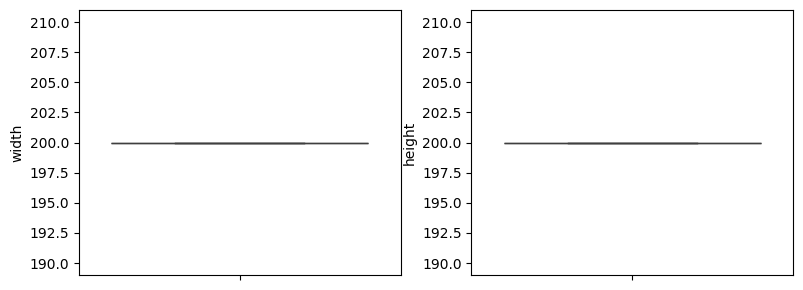

In [ ]:
print(df[['width', 'height']].describe())   # summary statistics

plt.figure(figsize=(8, 3))
plt.subplot(1, 2, 1)
sns.boxplot(y='width', data=df)      # boxplot method from class
plt.subplot(1, 2, 2)
sns.boxplot(y='height', data=df)
plt.tight_layout()
plt.show()

In [ ]:
# How many images there are of each size and colour mode
print(df.groupby(['width', 'height', 'mode']).size())

width  height  mode
200    200     RGB     1799
dtype: int64


In [ ]:
df = df.reset_index(drop=True)

CLEAN_CSV = '/content/drive/MyDrive/SemProject/clean_data.csv'
df.to_csv(CLEAN_CSV, index=False)      # export, as shown in class

print('Clean images:', df.shape[0])
print(df['label'].value_counts())      # images per class after cleaning

Clean images: 1799
label
scratches          300
pitted_surface     300
rolled-in_scale    300
inclusion          300
crazing            300
patches            299
Name: count, dtype: int64


EXPLORATORY DATA ANALYSIS (EDA)


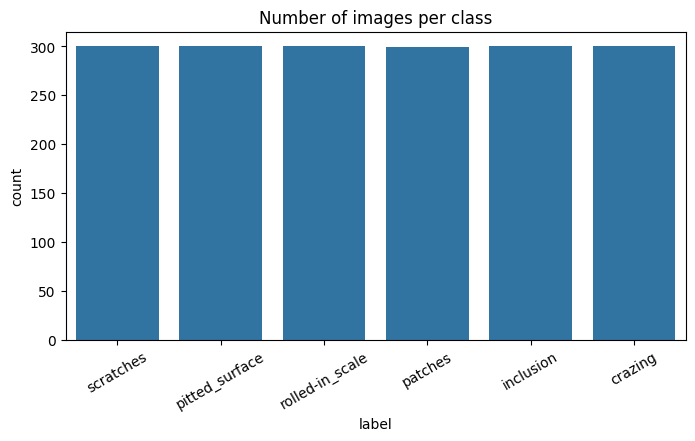

In [ ]:
# Bar chart of how many images each class has
plt.figure(figsize=(8, 4))
sns.countplot(x='label', data=df)
plt.title('Number of images per class')
plt.xticks(rotation=30)
plt.show()

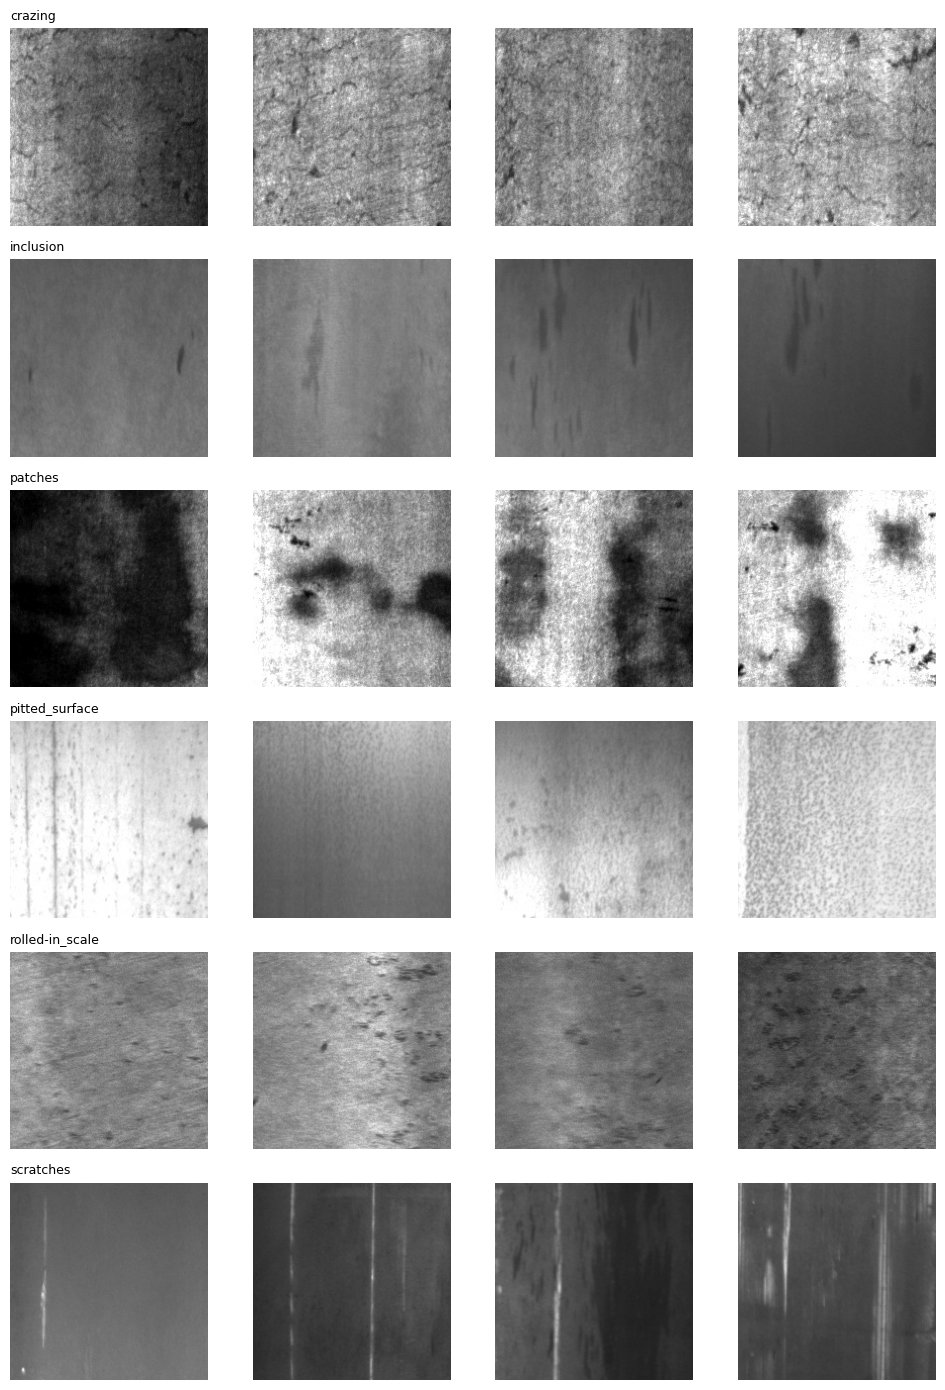

In [ ]:
# Show 4 random images from each class (rows = classes)
classes = sorted(df['label'].unique())

plt.figure(figsize=(10, 14))
n = 1
for c in classes:
    samples = df[df['label'] == c].sample(4, random_state=1)
    for path in samples['path']:
        plt.subplot(6, 4, n)
        plt.imshow(Image.open(path))
        plt.axis('off')
        if n % 4 == 1:
            plt.title(c, loc='left', fontsize=9)   # class name above the first image of each row
        n += 1
plt.tight_layout()
plt.show()

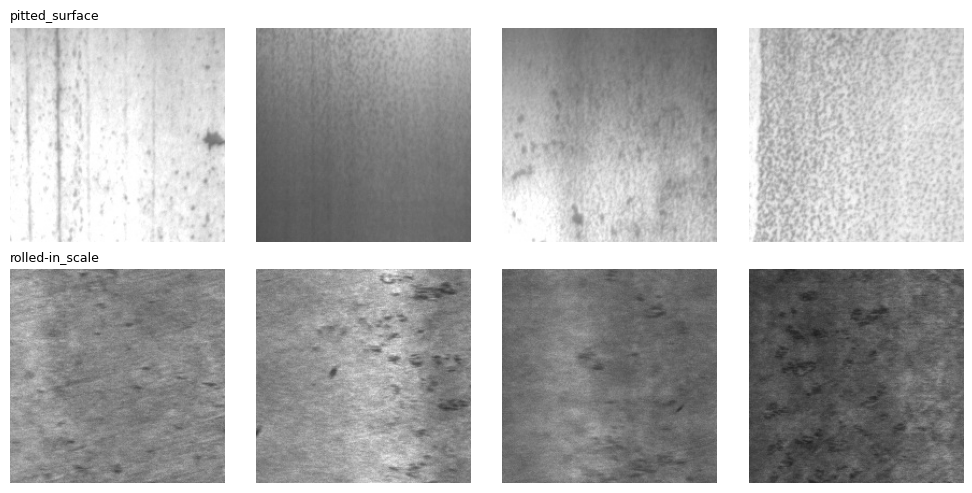

In [ ]:
# Show 4 random images from the two classes we have not looked at yet
plt.figure(figsize=(10, 5))
n = 1
for c in ['pitted_surface', 'rolled-in_scale']:
    samples = df[df['label'] == c].sample(4, random_state=1)
    for path in samples['path']:
        plt.subplot(2, 4, n)
        plt.imshow(Image.open(path))
        plt.axis('off')
        if n % 4 == 1:
            plt.title(c, loc='left', fontsize=9)
        n += 1
plt.tight_layout()
plt.show()

Images where R = G = B: 1799 of 1799
                 count        mean        std        min         25%  \
label                                                                  
crazing          300.0  141.107116  28.668897  60.224950  119.115013   
inclusion        300.0  106.366375  33.873650  49.893825   84.896556   
patches          299.0  132.564614  43.126494  35.567475  105.961737   
pitted_surface   300.0  176.665727  49.347109  44.465675  148.076819   
rolled-in_scale  300.0  117.912608  24.624031  68.810200   93.289062   
scratches        300.0   95.145790  29.087728  34.336950   73.343131   

                        50%         75%         max  
label                                                
crazing          149.028363  164.862088  183.593225  
inclusion         99.399000  116.360838  233.433925  
patches          139.601200  162.533062  223.669750  
pitted_surface   186.357200  217.778894  246.112525  
rolled-in_scale  125.867463  136.659937  160.962750  
scratche

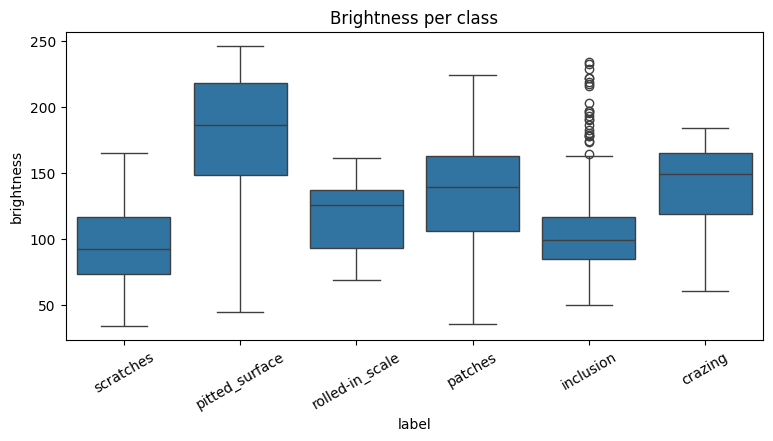

In [ ]:
# Average brightness of each image (0 = black, 255 = white)
# and a check on whether the 3 colour channels (R, G, B) are identical
brightness = []
same_channels = []

for path in df['path']:
    img = np.array(Image.open(path))          # image as numbers, shape (200, 200, 3)
    brightness.append(img.mean())
    same_channels.append(bool((img[:, :, 0] == img[:, :, 1]).all() and (img[:, :, 1] == img[:, :, 2]).all()))

df['brightness'] = brightness
df['same_channels'] = same_channels

print('Images where R = G = B:', df['same_channels'].sum(), 'of', df.shape[0])
print(df.groupby('label')['brightness'].describe())   # brightness summary per class

plt.figure(figsize=(9, 4))
sns.boxplot(x='label', y='brightness', data=df)     # boxplot method from class
plt.xticks(rotation=30)
plt.title('Brightness per class')
plt.show()

ADDING OUR OWN SPIN


In [ ]:
# Our own grouping of the 6 defect types into 3 severity levels
severity_map = {
    'patches': 'low',
    'crazing': 'low',
    'rolled-in_scale': 'medium',
    'inclusion': 'medium',
    'pitted_surface': 'high',
    'scratches': 'high'
}

df['severity'] = df['label'].map(severity_map)

print(df['severity'].value_counts())        # images per severity level
print(df.groupby(['severity', 'label']).size())

severity
high      600
medium    600
low       599
Name: count, dtype: int64
severity  label          
high      pitted_surface     300
          scratches          300
low       crazing            300
          patches            299
medium    inclusion          300
          rolled-in_scale    300
dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

# Step 1: take out 200 images for the TEST set (never used for training or tuning)
train_val_df, test_df = train_test_split(
    df, test_size=200, stratify=df['label'], random_state=42)

# Step 2: from the rest, take out 200 images for the VALIDATION set
train_df, val_df = train_test_split(
    train_val_df, test_size=200, stratify=train_val_df['label'], random_state=42)

print('Training images:  ', train_df.shape[0])
print('Validation images:', val_df.shape[0])
print('Test images:      ', test_df.shape[0])

# Check that no image appears in two sets (the sets must not overlap)
print('Train/validation overlap:', len(set(train_df['path']) & set(val_df['path'])))
print('Train/test overlap:      ', len(set(train_df['path']) & set(test_df['path'])))
print('Validation/test overlap: ', len(set(val_df['path']) & set(test_df['path'])))

# Check that each set has a similar mix of severity levels
print(pd.DataFrame({
    'train': train_df['severity'].value_counts(),
    'validation': val_df['severity'].value_counts(),
    'test': test_df['severity'].value_counts()}))

Training images:   1399
Validation images: 200
Test images:       200
Train/validation overlap: 0
Train/test overlap:       0
Validation/test overlap:  0
          train  validation  test
severity                         
high        467          67    66
low         466          66    67
medium      466          67    67


In [ ]:
# Numbers for the model: low = 0, medium = 1, high = 2
severity_codes = {'low': 0, 'medium': 1, 'high': 2}

# Label each set, then add the numeric label
train_df = train_df.copy(); train_df['split'] = 'train'
val_df   = val_df.copy();   val_df['split']   = 'validation'
test_df  = test_df.copy();  test_df['split']  = 'test'

for d in [train_df, val_df, test_df]:
    d['y'] = d['severity'].map(severity_codes)

# Save everything in one file so the same split can be reloaded later
all_df = pd.concat([train_df, val_df, test_df])
all_df.to_csv('/content/drive/MyDrive/SemProject/split_data.csv', index=False)

print(all_df.groupby(['split', 'severity', 'y']).size())

split       severity  y
test        high      2     66
            low       0     67
            medium    1     67
train       high      2    467
            low       0    466
            medium    1    466
validation  high      2     67
            low       0     66
            medium    1     67
dtype: int64


In [ ]:
IMG_SIZE = 224   # MobileNetV2 works with 224 x 224 images

def load_images(frame):
    # Open each image, make sure it has 3 channels, resize it, and turn it into numbers
    images = []
    for path in frame['path']:
        img = Image.open(path).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
        images.append(np.array(img))
    return np.array(images, dtype='uint8')

X_train = load_images(train_df); y_train = train_df['y'].values
X_val   = load_images(val_df);   y_val   = val_df['y'].values
X_test  = load_images(test_df);  y_test  = test_df['y'].values

print('X_train:', X_train.shape, ' y_train:', y_train.shape)
print('X_val:  ', X_val.shape,   ' y_val:  ', y_val.shape)
print('X_test: ', X_test.shape,  ' y_test: ', y_test.shape)
print('Pixel range:', X_train.min(), 'to', X_train.max())

X_train: (1399, 224, 224, 3)  y_train: (1399,)
X_val:   (200, 224, 224, 3)  y_val:   (200,)
X_test:  (200, 224, 224, 3)  y_test:  (200,)
Pixel range: 0 to 255


Training set before augmentation: 1399
Training set after augmentation:  4197
Images per severity level: [1398 1398 1401]


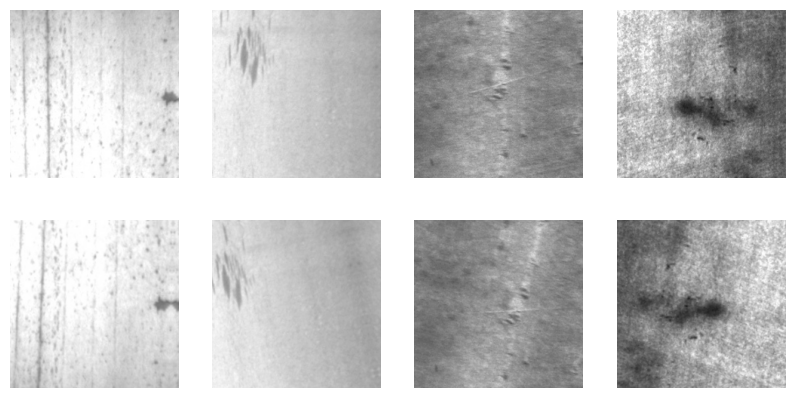

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Mild changes only (no brightness change)
datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    vertical_flip=True,
     fill_mode='reflect')

# Start with the original training images, then add 2 augmented copies of every image
all_images = [X_train]
all_labels = [y_train]
for i in range(2):
    batch = datagen.flow(X_train, y_train, batch_size=len(X_train), shuffle=False, seed=i)
    xb, yb = next(batch)
    all_images.append(np.clip(xb, 0, 255).astype('uint8'))
    all_labels.append(yb.astype(int))

X_train_aug = np.concatenate(all_images)
y_train_aug = np.concatenate(all_labels)

print('Training set before augmentation:', X_train.shape[0])
print('Training set after augmentation: ', X_train_aug.shape[0])
print('Images per severity level:', np.bincount(y_train_aug))

# Preview: 4 originals (top row) and their augmented versions (bottom row)
plt.figure(figsize=(10, 5))
for k in range(4):
    plt.subplot(2, 4, k + 1);     plt.imshow(X_train[k]);                      plt.axis('off')
    plt.subplot(2, 4, k + 5);     plt.imshow(X_train_aug[len(X_train) + k]);   plt.axis('off')
plt.show()

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

# Pretrained MobileNetV2 (already learned to see shapes and textures from millions of images)
base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False       # freeze it, so only our new layers learn

# Our model: scale pixels to 0-1, pretrained base, then a small classifier on top
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1.0 / 255),                 # turn 0-255 into 0-1
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),                         # helps against overfitting
    layers.Dense(128, activation='relu'),
    layers.Dense(3, activation='softmax')        # 3 outputs: low, medium, high
])

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

TRAINING AND VALIDATION

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Stop if the validation loss does not improve for 4 rounds, and keep the best version
early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)

# Save the best model to Drive
checkpoint = ModelCheckpoint('/content/drive/MyDrive/SemProject/model_base.keras',
                             monitor='val_loss', save_best_only=True)

history = model.fit(
    X_train_aug, y_train_aug,                 # training data (augmented)
    validation_data=(X_val, y_val),           # validation data (never trained on)
    epochs=15,
    batch_size=32,
    callbacks=[early_stop, checkpoint])

Epoch 1/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 208s 2s/step - accuracy: 0.9562 - loss: 0.1136 - val_accuracy: 0.9850 - val_loss: 0.0378
Epoch 2/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 197s 1s/step - accuracy: 0.9914 - loss: 0.0256 - val_accuracy: 0.9900 - val_loss: 0.0151
Epoch 3/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 196s 1s/step - accuracy: 0.9962 - loss: 0.0149 - val_accuracy: 0.9900 - val_loss: 0.0332
Epoch 4/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 193s 1s/step - accuracy: 0.9919 - loss: 0.0240 - val_accuracy: 1.0000 - val_loss: 0.0065
Epoch 5/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 195s 1s/step - accuracy: 0.9929 - loss: 0.0193 - val_accuracy: 0.9900 - val_loss: 0.0157
Epoch 6/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 194s 1s/step - accuracy: 0.9969 - loss: 0.0086 - val_accuracy: 0.9900 - val_loss: 0.0266
Epoch 7/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 196s 1s/step - accuracy: 0.9943 - loss: 0.0184 - val_accuracy: 0.9950 - val_loss: 0.0090
Epoch 8/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 203s 1s/step - accuracy: 0.9964 - loss: 0.0109 - val_accu

TESTING

7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step
Test accuracy: 0.865
              precision    recall  f1-score   support

         low       0.96      0.85      0.90        79
      medium       0.82      0.96      0.88        72
        high       0.80      0.76      0.78        49

    accuracy                           0.86       200
   macro avg       0.86      0.85      0.85       200
weighted avg       0.87      0.86      0.86       200

Cohen's kappa: 0.794


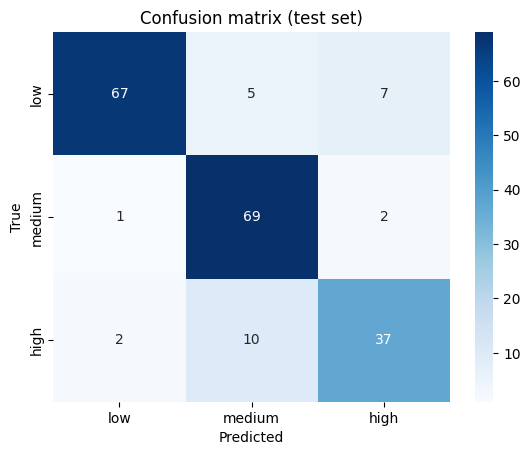

In [ ]:
from tensorflow.keras.models import load_model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, cohen_kappa_score
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load the best saved model
model = load_model('/content/drive/MyDrive/SemProject/model_mixed.keras')

# 2. Predict on the 200 test images
y_pred = np.argmax(model.predict(X_test), axis=1)

# 3. Overall results
names = ['low', 'medium', 'high']
print('Test accuracy:', round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred, labels=[0, 1, 2], target_names=names, zero_division=0))
print("Cohen's kappa:", round(cohen_kappa_score(y_test, y_pred), 3))

# 4. Confusion matrix
sns.heatmap(confusion_matrix(y_test, y_pred, labels=[0, 1, 2]), annot=True, fmt='d',
            cmap='Blues', xticklabels=names, yticklabels=names)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Confusion matrix (test set)')
plt.show()